# Teplota Prahy z Landsatu 8: Planckův zákon v praxi

[![Otevřít v Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_cs.ipynb)

**OpenSkyLab · notebook k vizuálu** [Záření černého tělesa](https://openskylab.space/edu_viz_blackbody_radiation.html) · [English version](blackbody_radiation_en.ipynb)

Vizuál ukazuje Planckův zákon, Wienův posun, čtvrtou mocninu Stefanova–Boltzmannova zákona a vliv emisivity. Tady stejné vzorce použiješ na skutečný termální snímek Landsatu 8 z vlny veder 26. června 2019 a z digitálních čísel spočítáš teplotu povrchu Prahy.

**Cíl:** převést termální pásmo Landsatu 8 z DN na zář a jasovou teplotu, opravit ji o emisivitu, odhadnout chybu ze špatné emisivity a odrazu oblohy a ukázat, proč družice hledají malé požáry ve 3,9 µm.

**Data:** Landsat 8 OLI/TIRS, Collection 1 Level-1, scéna `LC08_L1TP_191025_20190626_20190705_01_T1` (26. 6. 2019, 9:51 UTC, oblačnost 0,1 %), pásma B4, B5 a B10 a soubor MTL s kalibračními konstantami z veřejného archivu Google Cloud. Čte se jen výřez 16 × 16 km kolem centra Prahy (asi 3 MB).

**Úkoly:** pět. Odpovědi piš do buněk *Tvoje odpověď* pod úkoly. Řádky označené `# ◀ parametr` můžeš měnit a buňku spustit znovu (Shift + Enter).

**Čas:** asi 45 min. Potřebuješ Google účet (Colab); nic se neinstaluje do počítače. Buňky spouštěj popořadě shora dolů.

## 1. Příprava

In [1]:
%pip install -q rasterio

Note: you may need to restart the kernel to use updated packages.


In [2]:
import numpy as np, requests
import matplotlib.pyplot as plt
import rasterio
from rasterio.windows import from_bounds
from pyproj import Transformer
from scipy.constants import h, c, k, sigma

def planck(lam_um, T):
    """Spektrální zář černého tělesa ve W·m⁻²·sr⁻¹·µm⁻¹ pro vlnovou délku v µm a teplotu v K."""
    lam = np.asarray(lam_um) * 1e-6
    return 2 * h * c**2 / lam**5 / np.expm1(h * c / (lam * k * T)) * 1e-6

def planck_inv(lam_um, L):
    """Jasová teplota (K): teplota černého tělesa, které by mělo zář L na vlnové délce lam_um."""
    lam = lam_um * 1e-6
    return h * c / (lam * k) / np.log1p(2 * h * c**2 / lam**5 / (np.asarray(L) * 1e6))

## 2. Planckův zákon, Wien a čtvrtá mocnina

  300 K: maximum   9.66 µm, tok      457.1 W/m² (σT⁴ =      459.3), zář v 10,9 µm     9.62 W·m⁻²·sr⁻¹·µm⁻¹
  600 K: maximum   4.83 µm, tok       7344 W/m² (σT⁴ =       7349), zář v 10,9 µm     96.5 W·m⁻²·sr⁻¹·µm⁻¹
  900 K: maximum   3.22 µm, tok   3.72e+04 W/m² (σT⁴ =   3.72e+04), zář v 10,9 µm      232 W·m⁻²·sr⁻¹·µm⁻¹
 5772 K: maximum   0.50 µm, tok  6.294e+07 W/m² (σT⁴ =  6.294e+07), zář v 10,9 µm 3.01e+03 W·m⁻²·sr⁻¹·µm⁻¹


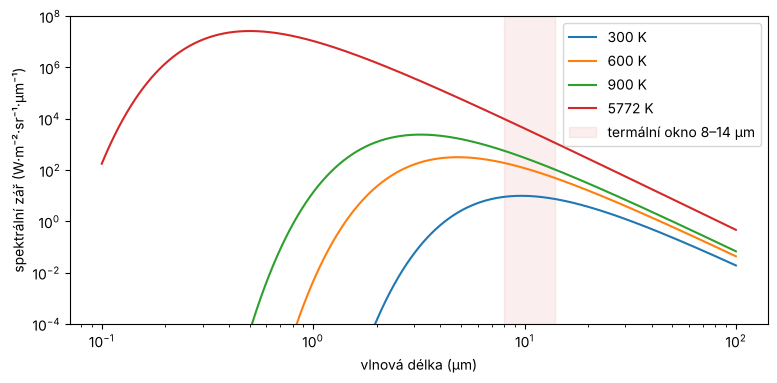

In [3]:
T_list = [300, 600, 900, 5772]      # ◀ parametr: teploty v K (krajina, kamna, požár, povrch Slunce)
lam = np.logspace(-1, 2, 2000)      # 0,1 až 100 µm
fig, ax = plt.subplots(figsize=(9, 4))
for T in T_list:
    L = planck(lam, T)
    ax.loglog(lam, L, label=f"{T} K")
    lmax = 2897.77 / T                                   # Wienův posunovací zákon, µm
    M = np.trapezoid(L, lam) * np.pi                     # zář → zářivý tok z plochy (W·m⁻²)
    print(f"{T:5d} K: maximum {lmax:6.2f} µm, tok {M:10.4g} W/m² (σT⁴ = {sigma * T**4:10.4g}), "
          f"zář v 10,9 µm {planck(10.9, T):8.3g} W·m⁻²·sr⁻¹·µm⁻¹")
ax.axvspan(8, 14, color="tab:red", alpha=0.08, label="termální okno 8–14 µm")
ax.set(xlabel="vlnová délka (µm)", ylabel="spektrální zář (W·m⁻²·sr⁻¹·µm⁻¹)", ylim=(1e-4, 1e8))
ax.legend(); plt.show()

> **✏️ Úkol 1.** Kolikrát vzroste celkový tok a kolikrát zář v 10,9 µm, když teplotu zdvojnásobíš z 300 na 600 K? Proč se obě čísla liší? Spočítej také, o kolik procent víc vyzáří asfalt o 45 °C než tráva o 25 °C.

*Tvoje odpověď:* 

## 3. Skutečná scéna: z DN na jasovou teplotu

Pásmo B10 (10,6–11,2 µm) ukládá digitální čísla (DN). Soubor MTL obsahuje lineární převod na zář, L = M · DN + A, a konstanty K1, K2, kterými se zář převede na jasovou teplotu, T = K2 / ln(K1 / L + 1). Je to Planckův zákon zjednodušený na jedno pásmo.

In [4]:
SCENE = "LC08_L1TP_191025_20190626_20190705_01_T1"
BASE = f"https://storage.googleapis.com/gcp-public-data-landsat/LC08/01/191/025/{SCENE}/{SCENE}"
mtl = dict(l.strip().split(" = ") for l in requests.get(BASE + "_MTL.txt", timeout=60).text.splitlines() if " = " in l)
num = lambda key: float(mtl[key])

lon, lat, half = 14.42, 50.08, 8000      # ◀ parametr: střed výřezu (°) a poloviční šířka (m)

def read_band(b):
    with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR", GDAL_HTTP_MAX_RETRY=5, GDAL_HTTP_RETRY_DELAY=2):
        with rasterio.open(f"/vsicurl/{BASE}_B{b}.TIF") as r:
            x, y = Transformer.from_crs(4326, r.crs, always_xy=True).transform(lon, lat)
            return r.read(1, window=from_bounds(x - half, y - half, x + half, y + half, r.transform)).astype(float)

dn10 = read_band(10)
L10 = num("RADIANCE_MULT_BAND_10") * dn10 + num("RADIANCE_ADD_BAND_10")
BT = num("K2_CONSTANT_BAND_10") / np.log(num("K1_CONSTANT_BAND_10") / L10 + 1)
print("datum a čas:", mtl["DATE_ACQUIRED"], mtl["SCENE_CENTER_TIME"].strip('"'), "| výška Slunce", mtl["SUN_ELEVATION"], "°")
print(f"DN {dn10.min():.0f}–{dn10.max():.0f} → zář {L10.min():.2f}–{L10.max():.2f} W·m⁻²·sr⁻¹·µm⁻¹ → "
      f"jasová teplota {BT.min() - 273.15:.1f} až {BT.max() - 273.15:.1f} °C")
print(f"kontrola Planckem pro 10,9 µm: {planck_inv(10.9, np.median(L10)) - 273.15:.1f} °C vs. K1/K2: {np.median(BT) - 273.15:.1f} °C")

datum a čas: 2019-06-26 09:50:52.4753079Z | výška Slunce 59.75814548 °
DN 26862–36973 → zář 9.08–12.46 W·m⁻²·sr⁻¹·µm⁻¹ → jasová teplota 23.1 až 45.5 °C
kontrola Planckem pro 10,9 µm: 33.4 °C vs. K1/K2: 33.6 °C


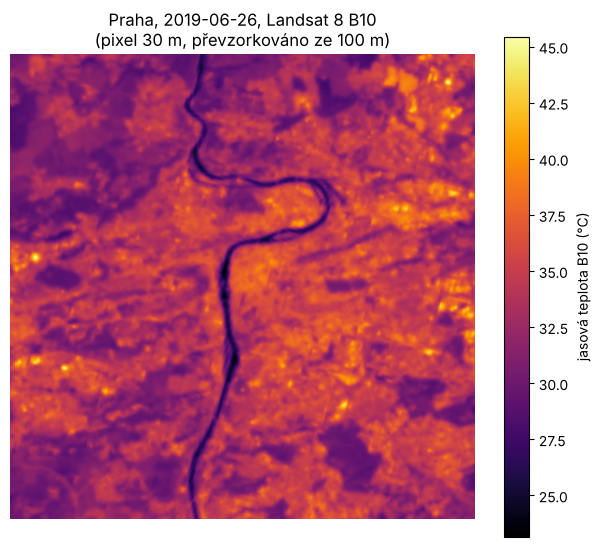

In [5]:
fig, ax = plt.subplots(figsize=(7.5, 6.5))
im = ax.imshow(BT - 273.15, cmap="inferno")
fig.colorbar(im, ax=ax, label="jasová teplota B10 (°C)")
ax.set_title(f"Praha, {mtl['DATE_ACQUIRED']}, Landsat 8 B10\n(pixel 30 m, převzorkováno ze 100 m)")
ax.axis("off"); plt.show()

> **✏️ Úkol 2.** Najdi na mapě Vltavu, velké parky nebo lesy (Stromovka, Hvězda, Krč) a zastavěné plochy s halami. Jaké jasové teploty mají? Proč je rozdíl mezi Vltavou a střechami hal kolem poledne tak velký? Proč není jasová teplota totéž co teplota povrchu?

*Tvoje odpověď:* 

## 4. Emisivita

Reálné povrchy vyzařují méně než černé těleso: L = ε · B(T). Emisivitu odhadneme z NDVI metodou prahů (Sobrino a kol. 2004): voda 0,991, holý povrch 0,97, plná vegetace 0,99, mezi tím podle podílu vegetace. Odraz oblohy a atmosféru zatím zanedbáme.

emisivita 0.970–0.991; oprava LST − BT: medián 0.55 K, rozsah 0.41 až 2.13 K


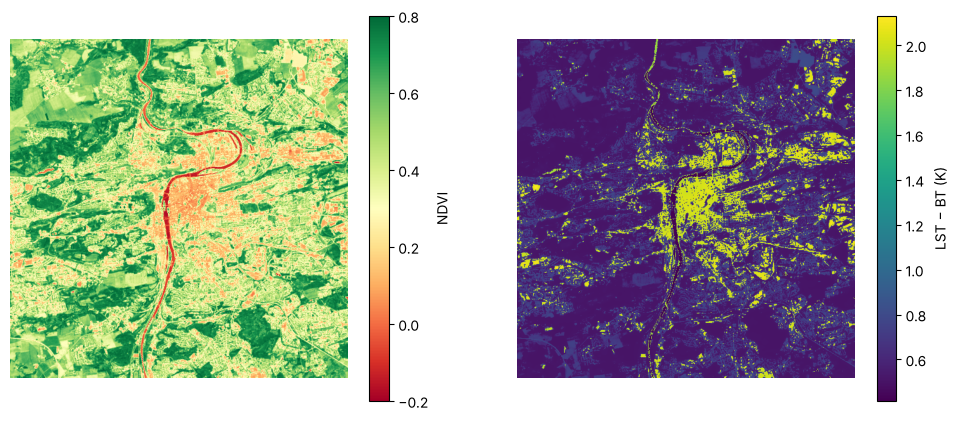

In [6]:
sun = np.sin(np.radians(num("SUN_ELEVATION")))
refl = lambda b: (num(f"REFLECTANCE_MULT_BAND_{b}") * read_band(b) + num(f"REFLECTANCE_ADD_BAND_{b}")) / sun
red, nir = refl(4), refl(5)
ndvi = (nir - red) / (nir + red)

eps_soil, eps_veg, eps_water = 0.97, 0.99, 0.991     # ◀ parametr: emisivity
ndvi_s, ndvi_v = 0.2, 0.5
pv = np.clip((ndvi - ndvi_s) / (ndvi_v - ndvi_s), 0, 1) ** 2          # podíl vegetace v pixelu
# poslední člen: dutinový efekt (vícenásobné odrazy mezi rostlinami a půdou), tvarový faktor 0,55
eps = np.where(ndvi < 0, eps_water, np.where(ndvi < ndvi_s, eps_soil, eps_veg * pv + eps_soil * (1 - pv) + (1 - eps_soil) * (1 - pv) * 0.55 * eps_veg))
LST = planck_inv(10.9, L10 / eps)            # teplota tělesa, které by s emisivitou ε mělo naměřenou zář
d = LST - BT
print(f"emisivita {eps.min():.3f}–{eps.max():.3f}; oprava LST − BT: medián {np.median(d):.2f} K, rozsah {d.min():.2f} až {d.max():.2f} K")
fig, ax = plt.subplots(1, 2, figsize=(12, 5))
a = ax[0].imshow(ndvi, cmap="RdYlGn", vmin=-0.2, vmax=0.8); fig.colorbar(a, ax=ax[0], label="NDVI")
b = ax[1].imshow(d, cmap="viridis"); fig.colorbar(b, ax=ax[1], label="LST − BT (K)")
for x in ax: x.axis("off")
plt.show()

In [7]:
# o kolik se splete senzor, když povrch s naměřenou zář má jinou emisivitu, než předpokládáme
T_true = 273.15 + 40          # ◀ parametr: skutečná teplota povrchu v K
for eps_true in (0.98, 0.95, 0.92, 0.85):
    L = eps_true * planck(10.9, T_true)
    print(f"ε = {eps_true:.2f}: jasová teplota {planck_inv(10.9, L) - 273.15:5.1f} °C, chyba {planck_inv(10.9, L) - T_true:+5.2f} K")

ε = 0.98: jasová teplota  38.5 °C, chyba -1.47 K
ε = 0.95: jasová teplota  36.3 °C, chyba -3.71 K
ε = 0.92: jasová teplota  34.0 °C, chyba -5.99 K
ε = 0.85: jasová teplota  28.5 °C, chyba -11.47 K


> **✏️ Úkol 3.** Kde je oprava o emisivitu největší a proč? Zhruba o kolik kelvinů se senzor splete na každou setinu emisivity? Změň `eps_soil` na 0,95 (beton, asfalt) a sleduj, jak se změní oprava v zastavěných plochách.

*Tvoje odpověď:* 

## 5. Odraz oblohy

Povrch s emisivitou ε odráží 1 − ε dlouhovlnného záření, které na něj svítí z oblohy. Jasná obloha je v 10 µm velmi studená, zatažená má zhruba teplotu základny oblačnosti. Senzor dostane L = ε · B(T) + (1 − ε) · B(T_obloha).

In [8]:
T_surf = 273.15 + 27           # ◀ parametr: teplota povrchu
for name, eps_m in [("tráva", 0.98), ("beton", 0.92), ("zoxidovaný plech", 0.6), ("lesklý hliník", 0.05)]:
    row = []
    for T_sky_c in (-40, -10, 10, 27):       # jasná obloha … nízká oblačnost … obloha teplá jako povrch
        L = eps_m * planck(10.9, T_surf) + (1 - eps_m) * planck(10.9, 273.15 + T_sky_c)
        row.append(f"{planck_inv(10.9, L) - 273.15:6.1f}")
    print(f"{name:18s} ε={eps_m:.2f}: jasová teplota při obloze −40/−10/+10/+27 °C:", " ".join(row), "°C")

tráva              ε=0.98: jasová teplota při obloze −40/−10/+10/+27 °C:   26.0   26.4   26.7   27.0 °C
beton              ε=0.92: jasová teplota při obloze −40/−10/+10/+27 °C:   23.1   24.5   25.7   27.0 °C
zoxidovaný plech   ε=0.60: jasová teplota při obloze −40/−10/+10/+27 °C:    5.7   13.7   20.5   27.0 °C
lesklý hliník      ε=0.05: jasová teplota při obloze −40/−10/+10/+27 °C:  -34.9   -7.8   10.9   27.0 °C


> **✏️ Úkol 4.** Proč lesklý plech pod jasnou oblohou vypadá v termokameře mrazivě studený, i když má 27 °C? Proč při obloze stejně teplé jako povrch nehraje emisivita žádnou roli? Za jakého počasí bys proto plánoval termální snímkování střech?

*Tvoje odpověď:* 

## 6. Požár menší než pixel

Pixel je směs: podíl p hoří při teplotě požáru, zbytek má teplotu pozadí. Jako pozadí vezmeme medián skutečné jasové teploty z výřezu Prahy a porovnáme pásmo 3,9 µm (jako MODIS a VIIRS) s pásmem 10,9 µm.

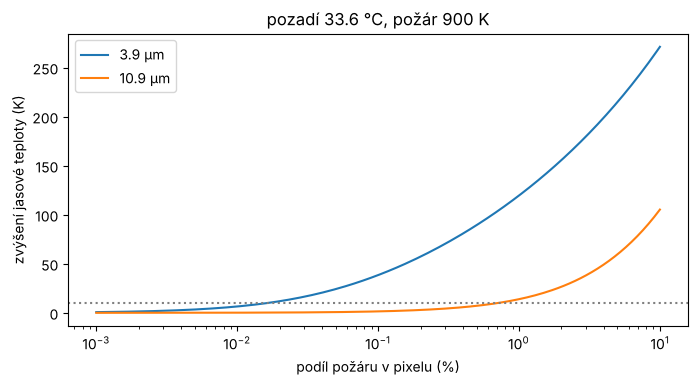

3.9 µm: o 10 K teplejší pixel už při podílu 0.017 % = 168 m² z pixelu 1 × 1 km
10.9 µm: o 10 K teplejší pixel už při podílu 0.715 % = 7149 m² z pixelu 1 × 1 km


In [9]:
T_fire = 900                     # ◀ parametr: teplota požáru v K
T_bg = float(np.median(BT))
p = np.logspace(-5, -1, 200)     # podíl požáru v pixelu
fig, ax = plt.subplots(figsize=(8, 3.8))
for lam_b in (3.9, 10.9):
    L = p * planck(lam_b, T_fire) + (1 - p) * planck(lam_b, T_bg)
    ax.semilogx(p * 100, planck_inv(lam_b, L) - T_bg, label=f"{lam_b} µm")
ax.axhline(10, color="gray", ls=":")
ax.set(xlabel="podíl požáru v pixelu (%)", ylabel="zvýšení jasové teploty (K)", title=f"pozadí {T_bg - 273.15:.1f} °C, požár {T_fire} K")
ax.legend(); plt.show()
for lam_b in (3.9, 10.9):
    L = p * planck(lam_b, T_fire) + (1 - p) * planck(lam_b, T_bg)
    p10 = p[np.argmax(planck_inv(lam_b, L) - T_bg > 10)]
    print(f"{lam_b} µm: o 10 K teplejší pixel už při podílu {p10 * 100:.3f} % = {p10 * 1e6:.0f} m² z pixelu 1 × 1 km")

> **✏️ Úkol 5.** Při jakém podílu požáru se pixel ohřeje o 10 K ve 3,9 µm a při jakém v 10,9 µm? Jakou plochu to je v pixelu MODIS 1 × 1 km? Vysvětli rozdíl Wienovým zákonem. Proč algoritmy ve dne hlídají i odražené Slunce ve 3,9 µm?

*Tvoje odpověď:* 

---
### Zdroje dat a literatura

- Landsat 8 OLI/TIRS Collection 1 Level-1, U.S. Geological Survey; veřejný archiv Google Cloud (`gcp-public-data-landsat`). Data USGS jsou volná bez omezení užití (public domain), s uvedením zdroje.
- Převod DN na zář a jasovou teplotu: USGS (2019). *Landsat 8 (L8) Data Users Handbook*, verze 5.0, kap. 5.
- Emisivita z NDVI: Sobrino, J. A., Jiménez-Muñoz, J. C., Paolini, L. (2004). Land surface temperature retrieval from LANDSAT TM 5. *Remote Sensing of Environment* 90, 434–440. https://doi.org/10.1016/j.rse.2004.02.003
- Detekce požárů ve 3,9 a 11 µm: Giglio, L., Schroeder, W., Justice, C. O. (2016). The collection 6 MODIS active fire detection algorithm and fire products. *Remote Sensing of Environment* 178, 31–41. https://doi.org/10.1016/j.rse.2016.02.054

### Jak citovat

OpenSkyLab (2026). Teplota Prahy z Landsatu 8: Planckův zákon v praxi [notebook, výukový materiál], verze 1.0. https://github.com/OpenSkyLab-space/notebooks/blob/main/blackbody_radiation_cs.ipynb. Licence CC BY 4.0.

Text a kód notebooku: OpenSkyLab, licence [CC BY 4.0](https://creativecommons.org/licenses/by/4.0/). Data mají licence svých poskytovatelů (viz výše).

*Materiál připravil tým OpenSkyLab s pomocí generativní AI Claude (Anthropic), která pomáhala s návrhem kódu a textu. Za obsah odpovídají autoři.*